In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_orig = pd.read_csv('ADNIMERGE_05Mar2026.csv')
df = df_orig.copy(deep=True)

df.describe(include='all')

C:\Users\ChiaraPollicini\AppData\Local\Temp\ipykernel_28884\4225207337.py:1: DtypeWarning: Columns (19,20,21,50,51,104,105,106) have mixed types. Specify dtype option on import or set low_memory=False.
  df_orig = pd.read_csv('ADNIMERGE_05Mar2026.csv')


,RID,COLPROT,ORIGPROT,PTID,SITE,VISCODE,EXAMDATE,DX_bl,AGE,PTGENDER,...,PTAU_bl,FDG_bl,PIB_bl,AV45_bl,FBB_bl,Years_bl,Month_bl,Month,M,update_stamp
count,16421.000000,16421,16421,16421,16421.000000,16421,16421,16410,16412.000000,16421,...,10083,11220.000000,154.000000,7836.000000,1099.000000,16421.000000,16421.000000,16421.000000,16421.000000,16421
unique,NaN,4,4,2430,NaN,37,4071,5,NaN,2,...,1409,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83
top,NaN,ADNI2,ADNI1,126_S_0605,NaN,bl,2011-12-05,LMCI,NaN,Male,...,18.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-07-07 04:59:48
freq,NaN,6945,7267,25,NaN,2430,19,5275,NaN,8981,...,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,914
mean,2899.082273,NaN,NaN,NaN,81.733329,NaN,NaN,NaN,73.214173,NaN,...,NaN,1.226786,1.582256,1.186525,1.163109,2.738280,32.792027,32.712259,32.580903,NaN
std,2220.442824,NaN,NaN,NaN,132.762777,NaN,NaN,NaN,7.028099,NaN,...,NaN,0.153364,0.302114,0.220110,0.236850,2.939675,35.203809,35.193789,35.124178,NaN
min,2.000000,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,50.400000,NaN,...,NaN,0.621933,1.155000,0.810000,0.870200,0.000000,0.000000,0.000000,0.000000,NaN
25%,751.000000,NaN,NaN,NaN,22.000000,NaN,NaN,NaN,68.500000,NaN,...,NaN,1.134820,1.360000,1.012400,0.995100,0.506502,6.065570,6.000000,6.000000,NaN
50%,2308.000000,NaN,NaN,NaN,41.000000,NaN,NaN,NaN,73.200000,NaN,...,NaN,1.234580,1.490000,1.098400,1.041700,1.960300,23.475400,24.000000,24.000000,NaN
75%,4707.000000,NaN,NaN,NaN,123.000000,NaN,NaN,NaN,78.100000,NaN,...,NaN,1.331470,1.835000,1.346900,1.318600,4.010950,48.032800,48.000000,48.000000,NaN


In [12]:
ap = [col for col in df.columns if col.startswith('AP')]
ap

['APOE4']

In [8]:
df['APOE4'].value_counts(dropna=False)

APOE4
0.0    9123
1.0    5578
2.0    1355
NaN     365
Name: count, dtype: int64

Colonne RAVLT: ['RAVLT_immediate', 'RAVLT_learning', 'RAVLT_forgetting', 'RAVLT_perc_forgetting', 'RAVLT_immediate_bl', 'RAVLT_learning_bl', 'RAVLT_forgetting_bl', 'RAVLT_perc_forgetting_bl']


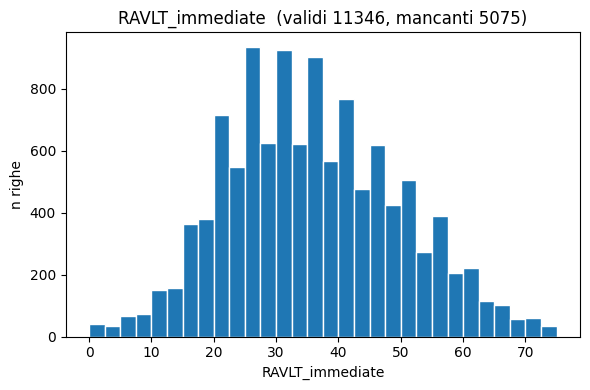

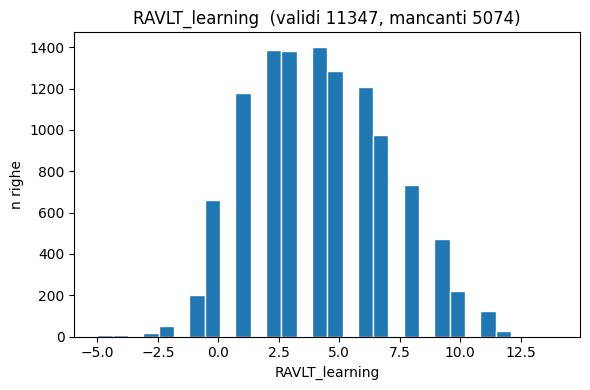

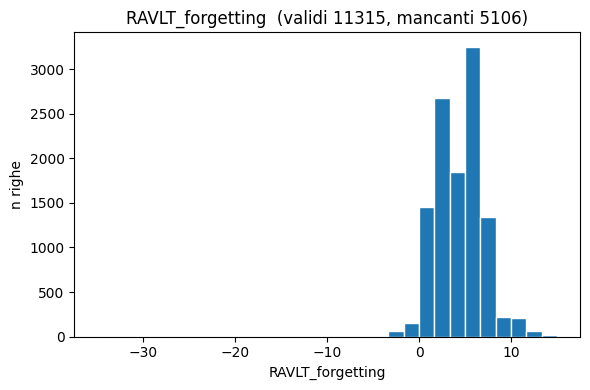

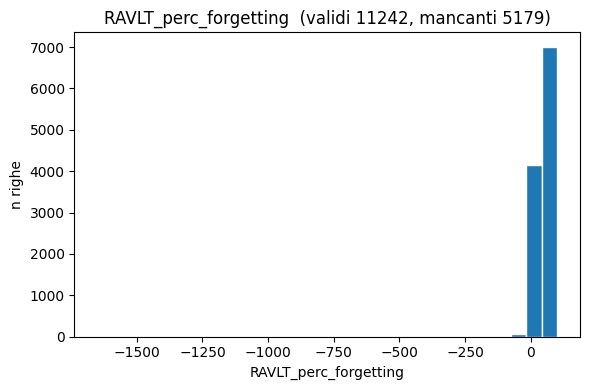

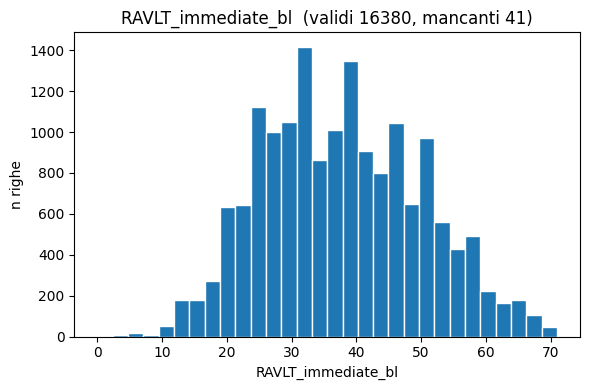

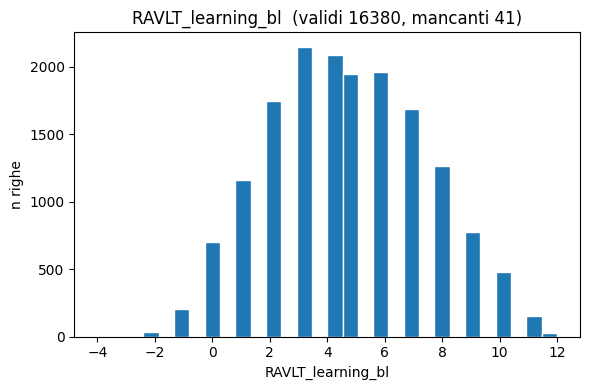

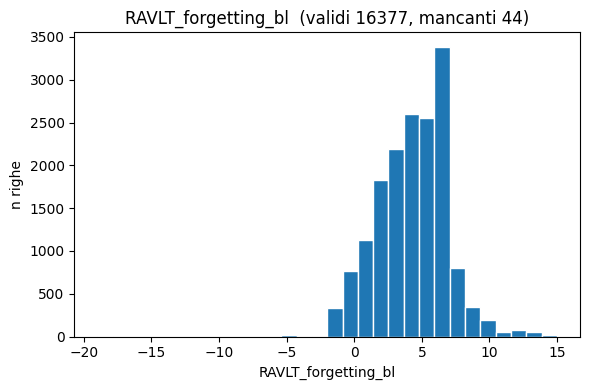

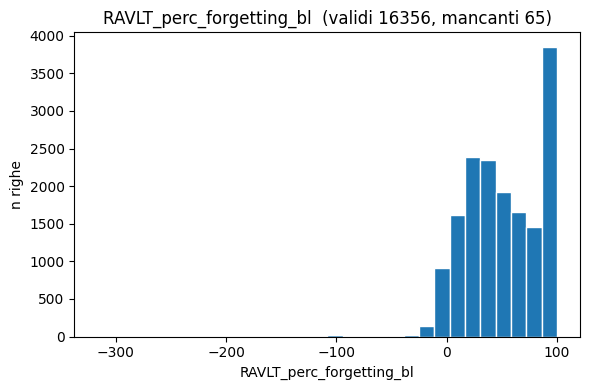

In [7]:
ravlt_list = [c for c in df.columns if c.startswith('RAVLT')]
print(f"Colonne RAVLT: {ravlt_list}")
for n, col in enumerate(ravlt_list):
    s = df[col]
    n_na = int(s.isna().sum())

    fig, ax = plt.subplots(figsize=(6, 4))
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().sum() == s.notna().sum() and s.nunique() > 10:
        # numerica continua -> istogramma
        ax.hist(num.dropna(), bins=30, edgecolor="white")
        ax.set_ylabel("n righe")
    else:
        # categorica o con pochi valori -> barre per valore
        s.value_counts(dropna=True).sort_index().plot.bar(ax=ax)
        ax.set_ylabel("n righe")
    ax.set_title(f"{col}  (validi {s.notna().sum()}, mancanti {n_na})")
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()